# Freight Rate Prediction

End-to-end walkthrough: explore → clean → features → time-based validation → model choice → final predictions.

The reusable pipeline functions live in `train.py`; this notebook imports them so the notebook and the script can never disagree.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

import train as T

pd.set_option('display.float_format', '{:,.2f}'.format)
raw_train = pd.read_csv(T.TRAIN)
raw_validation = pd.read_csv(T.VALIDATION)
for name, df in [('train', raw_train), ('validation', raw_validation)]:
    print(f"{name:<10} rows={len(df):,}  dates {df.date.min()} -> {df.date.max()}")
raw_train.head()

train      rows=48,000  dates 2025-01-01 -> 2025-10-31
validation rows=12,000  dates 2025-11-01 -> 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09,-76.79,38.17,-72.75,274.30,Dry Van,"30,658.00",2025-01-01,0.96,2.40,645.41
1,TR-000002,Richmond,Philadelphia,38.09,-76.79,39.22,-72.97,280.50,Reefer,"17,555.00",2025-01-01,0.98,2.43,679.97
2,TR-000003,Philadelphia,Green Bay,39.22,-72.97,44.30,-87.53,967.80,Dry Van,"31,721.00",2025-01-01,1.01,1.84,"1,802.54"
3,TR-000004,Hartford,Atlanta,39.55,-72.18,34.85,-86.29,965.40,Dry Van,"32,333.00",2025-01-01,0.95,1.88,"1,827.28"
4,TR-000005,Dallas,Nashville,31.83,-94.38,35.29,-88.09,541.90,Reefer,"35,183.00",2025-01-01,0.98,2.56,"1,380.28"


## 1. Exploration
Validation is **Nov–Dec**, training is **Jan–Oct**: we are forecasting the future, which drives the split choice later.

distance        0.91
weight          0.03
market_index    0.03
quote_signal   -0.04
posted_rate     1.00
Name: posted_rate, dtype: float64


equipment
Dry Van   2.05
Flatbed   2.22
Reefer    2.31
Name: median $/mile, dtype: float64

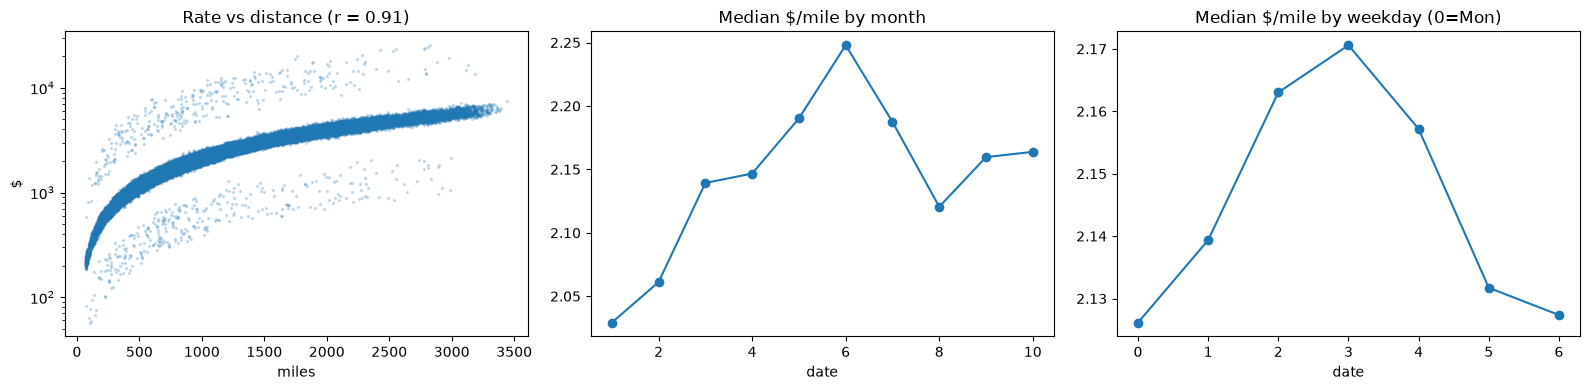

In [2]:
t = raw_train.assign(date=pd.to_datetime(raw_train.date), rpm=raw_train.posted_rate / raw_train.distance)
print(t[['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate']].corr()['posted_rate'].round(2))

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(t.distance, t.posted_rate, s=2, alpha=0.2)
ax[0].set(title='Rate vs distance (r = 0.91)', xlabel='miles', ylabel='$', yscale='log')
t.groupby(t.date.dt.month).rpm.median().plot(ax=ax[1], marker='o', title='Median $/mile by month')
t.groupby(t.date.dt.day_of_week).rpm.median().plot(ax=ax[2], marker='o', title='Median $/mile by weekday (0=Mon)')
plt.tight_layout()
t.groupby('equipment').rpm.median().rename('median $/mile')

In [3]:
seen = set(raw_train.pickup) | set(raw_train.delivery)
unseen = (set(raw_validation.pickup) | set(raw_validation.delivery)) - seen
rows = (~raw_validation.pickup.isin(seen) | ~raw_validation.delivery.isin(seen)).sum()
print(f'Cities in validation never seen in training: {sorted(unseen)}')
print(f'Validation rows affected: {rows:,} ({rows / len(raw_validation):.0%})')

Cities in validation never seen in training: ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']
Validation rows affected: 1,447 (12%)


## 2. Data quality
Negative weights, missing values, and — most importantly — mispriced loads.

In [4]:
pd.Series({
    'negative weight': (raw_train.weight < 0).sum(),
    'missing weight': raw_train.weight.isna().sum(),
    'missing market_index': raw_train.market_index.isna().sum(),
    'duplicate load_id': raw_train.load_id.duplicated().sum(),
}, name='rows')

negative weight         292
missing weight          300
missing market_index    374
duplicate load_id         0
Name: rows, dtype: int64

**Mispriced loads.** $/mile divided by the equipment median sits in 0.7–1.5× for 98.5% of rows. The rest form separate clusters (~0.1–0.5× and ~2–6×) — typo/decimal errors. Red lines = the cut-offs used.

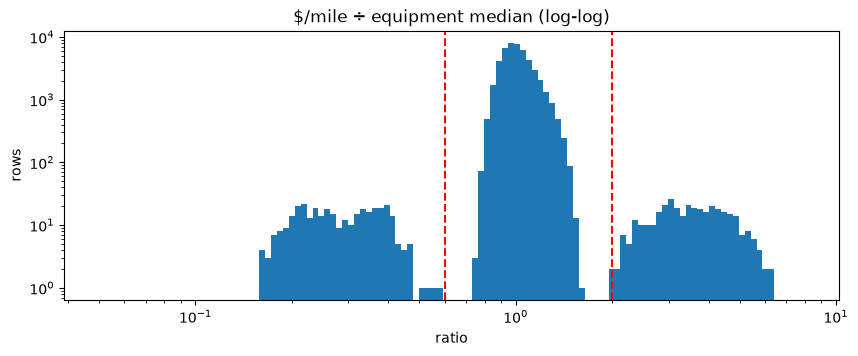

,pickup,delivery,distance,equipment,posted_rate,rpm
40322,Montgomery,El Paso,"1,639.90",Dry Van,"14,949.25",9.12
2221,Boston,Jacksonville,"1,166.10",Flatbed,"11,210.34",9.61
24784,New Orleans,Bakersfield,"1,656.10",Dry Van,"1,175.34",0.71
12306,Boston,Milwaukee,"1,194.50",Reefer,"1,067.60",0.89
29055,El Paso,Indianapolis,"1,450.00",Dry Van,667.86,0.46


In [5]:
ratio = t.rpm / t.groupby('equipment').rpm.transform('median')
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(ratio, bins=np.logspace(-1.3, 0.9, 120), log=True)
ax.set_xscale('log')
for x in (T.OUTLIER_LOW, T.OUTLIER_HIGH):
    ax.axvline(x, color='red', ls='--')
ax.set(title='$/mile ÷ equipment median (log-log)', xlabel='ratio', ylabel='rows')
plt.show()
t[(ratio > T.OUTLIER_HIGH) | (ratio < T.OUTLIER_LOW)].sample(5, random_state=0)[['pickup', 'delivery', 'distance', 'equipment', 'posted_rate', 'rpm']]

In [6]:
equipment_types = sorted(raw_train.equipment.unique())
train = T.clean_features(raw_train, equipment_types)  # abs(weight), mi_missing flag, calendar features
train, n_dropped = T.drop_label_outliers(train)
print(f'Dropped {n_dropped} mispriced rows ({n_dropped / len(raw_train):.1%}); {len(train):,} rows remain')
print('Features:', T.FEATURES)

Dropped 675 mispriced rows (1.4%); 47,325 rows remain
Features: ['equipment', 'distance', 'weight', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'market_index', 'mi_missing', 'quote_signal', 'month', 'dow', 'doy']


## 3. Validation strategy
Split by **time**, not randomly: train Jan–Aug, test Sep–Oct mirrors the real task (train Jan–Oct, predict Nov–Dec). Compared against two simple baselines.

Model target: `log(rate / distance)`, converted back × distance.

In [7]:
holdout_train, holdout_test = train[train.month <= 8], train[train.month >= 9]
results = T.evaluate(holdout_train, holdout_test)
rows = results.pop('rows')
print(f"train {rows['train']:,} rows | test {rows['test']:,} rows")
pd.DataFrame(results).T

train 37,945 rows | test 9,380 rows


,MAE,MAPE_%,RMSE
model,54.14,2.12,95.35
baseline_equipment,175.54,8.10,261.89
baseline_lane,88.65,3.75,142.89


**Expanding-window backtest** — does the result hold across periods?

In [8]:
pd.DataFrame({
    f'train 1-{k} → test {k+1}-{k+2}': T.evaluate(train[train.month <= k], train[train.month.between(k + 1, k + 2)])['model']
    for k in (4, 6, 8)
}).T

,MAE,MAPE_%,RMSE
train 1-4 → test 5-6,55.07,2.02,103.97
train 1-6 → test 7-8,104.76,4.40,166.81
train 1-8 → test 9-10,54.14,2.12,95.35


Jul–Aug is hardest: it follows the June peak, a turn the model has never seen.

## 4. City names vs coordinates
12% of validation rows involve an unseen city. Simulate that: hide 8 random cities from training, compare a model with city-name features vs coordinates only.

In [9]:
base = list(T.FEATURES)
cities = sorted(seen | unseen)
city_train = train.assign(**{c: pd.Categorical(train[c], categories=cities) for c in ('pickup', 'delivery')})
rng = np.random.default_rng(0)
rows = []
for trial in range(3):
    hide = set(rng.choice(sorted(seen), 8, replace=False))
    tr = city_train[(city_train.month <= 8) & ~city_train.pickup.isin(hide) & ~city_train.delivery.isin(hide)]
    te = city_train[city_train.month >= 9]
    is_unseen = (te.pickup.isin(hide) | te.delivery.isin(hide)).to_numpy()
    for name, feats in [('with city names', base + ['pickup', 'delivery']), ('coordinates only', base)]:
        T.FEATURES = feats
        p = T.predict(T.fit(tr), te)
        rows.append({'trial': trial, 'model': name,
                     'MAPE seen %': T.metrics(te.posted_rate[~is_unseen], p[~is_unseen])['MAPE_%'],
                     'MAPE unseen %': T.metrics(te.posted_rate[is_unseen], p[is_unseen])['MAPE_%']})
T.FEATURES = base
pd.DataFrame(rows).pivot(index='trial', columns='model')

MAPE seen %                    MAPE unseen %                
model coordinates only with city names coordinates only with city names
trial                                                                  
0                 2.04            2.00             2.21            2.68
1                 2.09            2.06             2.06            2.19
2                 2.05            2.01             2.16            2.09

Coordinates win on unseen cities in 2 of 3 trials at negligible cost on seen ones → **coordinates only**.

## 5. What drives the model
Permutation importance on the Sep–Oct holdout (how much error rises when a feature is shuffled).

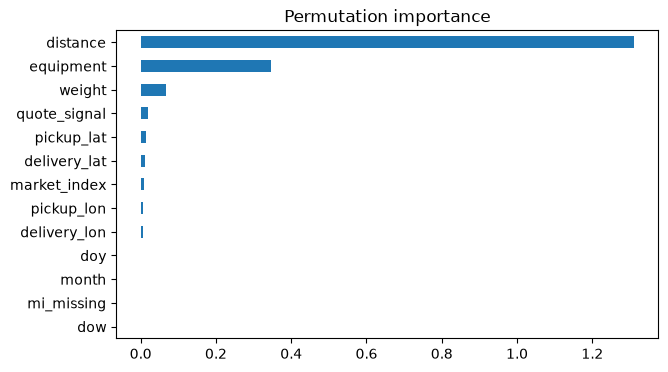

In [10]:
model = T.fit(holdout_train)
target = np.log(holdout_test.posted_rate / holdout_test.distance)
imp = permutation_importance(model, holdout_test[T.FEATURES], target, n_repeats=3, random_state=T.SEED)
pd.Series(imp.importances_mean, index=T.FEATURES).sort_values().plot.barh(figsize=(7, 4), title='Permutation importance');

## 6. Final model and predictions
Refit on all cleaned Jan–Oct data, predict the 12,000 validation loads, and fill the December chart inputs (market signals per date taken from validation's December rows; coordinates from the city lookup). `T.main()` does exactly this and writes the files.

In [ ]:
import contextlib, io
with contextlib.redirect_stdout(io.StringIO()):  
    T.main()
preds = pd.read_csv('validation_predictions.csv')
print(preds.shape, '| predicted_rate:', preds.predicted_rate.describe()[['min', 'mean', 'max']].round(0).to_dict())
pd.read_csv(T.DECEMBER).head()

(12000, 2) | predicted_rate: {'min': 182.0, 'mean': 2368.0, 'max': 6854.0}


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,804.25
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,810.93
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,815.12
3,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-04,817.98
4,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-05,814.69


In [12]:
import sys
!"{sys.executable}" score.py --predictions validation_predictions.csv --december-predictions december-chart-inputs.csv

Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


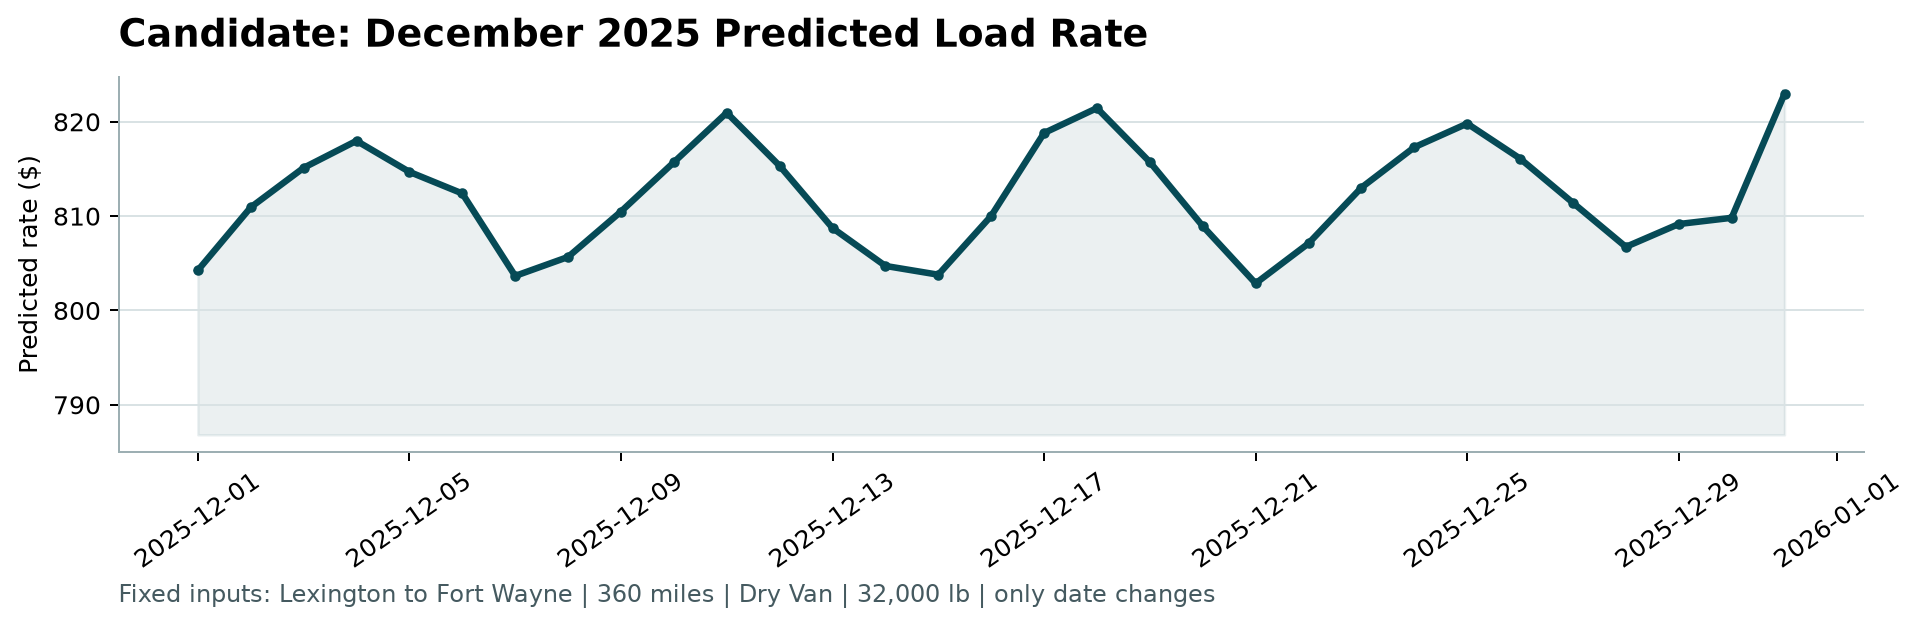

In [13]:
from IPython.display import Image
Image('scorer_results/candidate_december.png')

December: narrow $803–823 band (~$2.25/mile for 360 mi Dry Van) with a mid-week peak, matching the weekday pattern. No holiday effect — training data has no December.